<a href="https://colab.research.google.com/github/davide-ario/BNN/blob/main/BNN_latent_ability_card.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelling ability as a latent variable: return to schooling with a Bayesian factor model

In [`BNN_returns_to_education_card.ipynb`](BNN_returns_to_education_card.ipynb),
adding IQ and the KWW test score as controls lowered the return to schooling
from about 7.2% to 5.7% per year. That correction is probably incomplete:
test scores measure ability **with error**, and controlling for a noisy
proxy removes only part of the bias.

Here ability is a **latent variable** $A_i$, estimated jointly with the
return to schooling. IQ and KWW are treated as two noisy measurements of
$A_i$. Ability is allowed to depend on family background, and it drives
both schooling and wages:

$$
\begin{aligned}
A_i &= Z_i'\delta + \eta_i, \quad \eta_i \sim N(0, 1) && \text{ability, correlated with background } Z_i\\
\text{IQ}_i &= \mu_1 + \lambda_1 A_i + e_{1i} && \text{measurement 1}\\
\text{KWW}_i &= \mu_2 + \lambda_2 A_i + \kappa' T_i + e_{2i} && \text{measurement 2 ($T_i$: test-timing adjustments)}\\
\text{educ}_i &= S_i'\gamma_e + \pi\,\text{nearc4}_i + \lambda_e A_i + u_i && \text{schooling}\\
\log w_i &= \beta\,\text{educ}_i + f(W_i) + \lambda_w A_i + \varepsilon_i && \text{wages}
\end{aligned}
$$

All error terms are independent normals. $f$ is either linear or a small
Bayesian neural network. Ability bias corresponds to $\lambda_e > 0$ and
$\lambda_w > 0$.

**Identification.** The factor structure identifies ability: two
measurements plus schooling are three indicators of the same factor. This
rests on three assumptions:

1. a single ability factor;
2. the measurement errors are independent of the schooling and wage errors;
3. both tests load positively on ability ($\lambda_1, \lambda_2 > 0$). This
   fixes the sign of $A_i$; without it the sampler finds degenerate
   solutions in which "ability" is unrelated to IQ.

College proximity enters the schooling equation but not the wage equation,
as in Card's IV strategy. We check whether it adds identifying information.

Unlike the regressions with test-score controls, the model uses **all 3,010
men**. For men without an IQ score, the IQ equation simply drops out of the
likelihood.

Everything is estimated by full MCMC (NUTS), not variational inference,
because the correlation between $\beta$, the loadings and $A_i$ is exactly
what matters here and mean-field ADVI ignores it. **The notebook takes about
25 minutes to run**, mostly for the BNN model in section 6.

## Setup

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q "pymc>=6.4" "arviz>=1.0" linearmodels
    !wget -q https://raw.githubusercontent.com/davide-ario/BNN/main/bnn_models.py

In [2]:
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

import bnn_models as bm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
SEED = 0
print(f"PyMC v{pm.__version__}")

PyMC v6.4.0


## 1. Data

In [3]:
URL = ("https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/"
       "master/csv/Ecdat/Schooling.csv")
df = pd.read_csv(URL, index_col=0)
for col in df.columns:  # yes/no indicators -> 1/0
    if set(df[col].dropna().unique()) <= {"yes", "no"}:
        df[col] = df[col].map({"yes": 1.0, "no": 0.0})
df["exp2"] = df["exp76"] ** 2 / 100
df["age2"] = df["age76"] ** 2 / 100

COMMON = ["black", "south76", "smsa76", "south66", "smsa66", "daded", "momed",
          "nodaded", "momdad14", "sinmom14", "step14"]
W_VARS = ["exp76", "exp2"] + COMMON   # wage equation (Card's Mincer controls)
S_VARS = ["age76", "age2"] + COMMON   # schooling equation
Z_VARS = ["black", "south66", "smsa66", "daded", "momed", "nodaded",
          "momdad14", "sinmom14", "step14"]  # background shaping ability
print(f"{len(df):,} men; IQ observed for {df['iqscore'].notna().sum():,}, "
      f"KWW for {df['kww'].notna().sum():,}")

3,010 men; IQ observed for 2,061, KWW for 2,963


Schooling enters the wage equation with potential experience (age −
schooling − 6), as in the Mincer equation. The schooling equation uses age
instead, because experience is itself a function of schooling.

### A problem with the KWW test

KWW was administered in 1966, when the men were 14–24 years old. The
correlations below show that it depends strongly on age and on schooling
completed *by then*. IQ, which is age-normed, depends on neither. A
measurement that partly reflects schooling violates assumption 2: the
latent factor would absorb part of the effect of schooling, and $\beta$
would be understated. We therefore compare three versions of the KWW
equation.

In [4]:
df[["iqscore", "kww", "ed76", "ed66", "age76", "lwage76"]].corr().round(2)

,iqscore,kww,ed76,ed66,age76,lwage76
iqscore,1.00,0.43,0.51,0.22,-0.06,0.21
kww,0.43,1.00,0.49,0.61,0.37,0.43
ed76,0.51,0.49,1.00,0.61,-0.01,0.31
ed66,0.22,0.61,0.61,1.00,0.56,0.46
age76,-0.06,0.37,-0.01,0.56,1.00,0.28
lwage76,0.21,0.43,0.31,0.46,0.28,1.00


## 2. Benchmarks

OLS with and without test-score controls (on the 2,040 men with both
scores) and Card's IV estimate (full sample). The other notebook also
reports double machine learning with a BNN: 6.95% without and 5.5% with
test-score controls.

In [5]:
rhs = " + ".join(W_VARS)
ab = df.dropna(subset=["iqscore", "kww"])
ols_full = smf.ols(f"lwage76 ~ ed76 + {rhs}", df).fit(cov_type="HC1")
ols_ab = smf.ols(f"lwage76 ~ ed76 + {rhs}", ab).fit(cov_type="HC1")
ols_ab_tests = smf.ols(f"lwage76 ~ ed76 + {rhs} + iqscore + kww", ab).fit(cov_type="HC1")
iv = IV2SLS.from_formula(
    f"lwage76 ~ 1 + {' + '.join(COMMON)} + [ed76 + exp76 + exp2 ~ nearc4 + age76 + age2]",
    df).fit(cov_type="robust")


def ci(est, se):
    return est, est - 1.645 * se, est + 1.645 * se


benchmarks = {
    "OLS, full sample": ci(ols_full.params["ed76"], ols_full.bse["ed76"]),
    "OLS, test-score sample": ci(ols_ab.params["ed76"], ols_ab.bse["ed76"]),
    "OLS + IQ + KWW controls": ci(ols_ab_tests.params["ed76"], ols_ab_tests.bse["ed76"]),
    "IV (college proximity)": ci(iv.params["ed76"], iv.std_errors["ed76"]),
}
pd.DataFrame(benchmarks, index=["return", "5%", "95%"]).T.round(4)

,return,5%,95%
"OLS, full sample",0.0716,0.0653,0.0779
"OLS, test-score sample",0.0737,0.0655,0.0818
OLS + IQ + KWW controls,0.0577,0.0481,0.0673
IV (college proximity),0.1234,0.0406,0.2062


## 3. The latent-ability model

Continuous regressors and test scores are standardised. Schooling and log
wages stay in their original units, so $\beta$ is directly the return per
year of schooling.

In [6]:
def standardise(M):
    M = np.asarray(M, dtype=float)
    return (M - M.mean(0)) / M.std(0)


Xw, Xs, Xz = (standardise(df[v]) for v in (W_VARS, S_VARS, Z_VARS))
educ = df["ed76"].to_numpy(float)
lwage = df["lwage76"].to_numpy(float)
near = df["nearc4"].to_numpy(float)
iq = ((df["iqscore"] - df["iqscore"].mean()) / df["iqscore"].std()).to_numpy()
kww = ((df["kww"] - df["kww"].mean()) / df["kww"].std()).to_numpy()
i_iq, i_kww = np.flatnonzero(~np.isnan(iq)), np.flatnonzero(~np.isnan(kww))
TIMING = {"none": None,
          "age": standardise(df[["age76"]]),
          "age + 1966 schooling": standardise(df[["age76", "ed66"]])}


def build_latent_model(kww_adjust="age", instrument=True, bnn_wages=False):
    """Bayesian factor model for ability, schooling and wages (see the top)."""
    T = TIMING[kww_adjust]
    with pm.Model() as model:
        # Ability, correlated with family background
        delta = pm.Normal("delta", 0, 1, shape=Xz.shape[1])
        eta = pm.Normal("eta", 0, 1, shape=len(df))
        A = pt.dot(Xz, delta) + eta

        # Measurement equations (positive loadings fix the sign of A)
        mu_m = pm.Normal("mu_m", 0, 1, shape=2)
        lam_iq = pm.HalfNormal("lam_iq", 1)
        lam_kww = pm.HalfNormal("lam_kww", 1)
        s_m = pm.HalfNormal("s_m", 1, shape=2)
        pm.Normal("iq", mu_m[0] + lam_iq * A[i_iq], s_m[0], observed=iq[i_iq])
        mu_kww = mu_m[1] + lam_kww * A[i_kww]
        if T is not None:
            kappa = pm.Normal("kappa", 0, 1, shape=T.shape[1])
            mu_kww = mu_kww + pt.dot(T[i_kww], kappa)
        pm.Normal("kww", mu_kww, s_m[1], observed=kww[i_kww])

        # Schooling
        a_e = pm.Normal("a_e", 13, 5)
        g_e = pm.Normal("g_e", 0, 2, shape=Xs.shape[1])
        lam_e = pm.Normal("lam_e", 0, 2)
        mu_e = a_e + pt.dot(Xs, g_e) + lam_e * A
        if instrument:
            mu_e = mu_e + pm.Normal("pi", 0, 2) * near
        pm.Normal("educ", mu_e, pm.HalfNormal("s_e", 3), observed=educ)

        # Wages
        a_w = pm.Normal("a_w", 6, 2)
        beta = pm.Normal("beta", 0, 0.5)
        lam_w = pm.Normal("lam_w", 0, 0.5)
        if bnn_wages:
            f = bm._mlp("h", Xw, Xw.shape[1], 10, 2, bm.relu,
                        np.random.default_rng(SEED))
        else:
            f = pt.dot(Xw, pm.Normal("g_w", 0, 0.5, shape=Xw.shape[1]))
        pm.Normal("lwage", a_w + beta * educ + f + lam_w * A,
                  pm.HalfNormal("s_w", 1), observed=lwage)
    return model


def sample(model, draws=1000):
    with model:
        return pm.sample(draws, tune=draws, chains=4, cores=2, target_accept=0.9,
                         initvals={"lam_iq": 0.5, "lam_kww": 0.5},
                         random_seed=SEED, progressbar=False)


KEY = ["beta", "lam_e", "lam_w", "lam_iq", "lam_kww"]


def diagnostics(idata):
    s = az.summary(idata, var_names=KEY + (["pi"] if "pi" in idata.posterior else []),
                   kind="diagnostics")
    return {"max r_hat": s["r_hat"].max(), "min ESS": s["ess_bulk"].min(),
            "divergences": int(idata.sample_stats["diverging"].sum())}

## 4. Linear model: how should KWW be measured?

Three versions of the KWW measurement equation, all with a linear wage
equation and college proximity in the schooling equation:

* **none**: KWW measures ability only;
* **age**: KWW also depends on age at the test, which is exogenous;
* **age + 1966 schooling**: KWW also depends on schooling completed when
  the test was taken. This removes the contamination, but 1966 schooling
  is itself partly caused by ability, so the adjustment also removes some
  genuine ability signal from KWW. Ability is then measured mostly by IQ.

In [7]:
fits = {}
for adj in TIMING:
    fits[f"latent, KWW adj.: {adj}"] = sample(build_latent_model(kww_adjust=adj))

pd.DataFrame({k: diagnostics(v) for k, v in fits.items()}).T

,max r_hat,min ESS,divergences
"latent, KWW adj.: none",1.013374,320.973565,0.0
"latent, KWW adj.: age",1.009389,770.039552,0.0
"latent, KWW adj.: age + 1966 schooling",1.005105,838.125764,0.0


All three converge: $\hat R \le 1.014$, at least 320 effective draws for
every key parameter, and no divergent transitions.

In [8]:
def posterior_summary(idata, var):
    x = idata.posterior[var].values.reshape(-1)
    return x.mean(), np.percentile(x, 5), np.percentile(x, 95)


pd.DataFrame({k: {v: f"{m:.3f} [{lo:.3f}, {hi:.3f}]"
                  for v in KEY + ["pi"]
                  for m, lo, hi in [posterior_summary(idata, v)]}
              for k, idata in fits.items()}).T

,beta,lam_e,lam_w,lam_iq,lam_kww,pi
"latent, KWW adj.: none","0.023 [0.006, 0.039]","1.695 [1.587, 1.808]","0.133 [0.095, 0.174]","0.549 [0.512, 0.586]","0.435 [0.407, 0.464]","0.214 [0.066, 0.360]"
"latent, KWW adj.: age","0.043 [0.033, 0.053]","1.533 [1.438, 1.626]","0.102 [0.075, 0.128]","0.604 [0.569, 0.638]","0.448 [0.425, 0.471]","0.210 [0.059, 0.360]"
"latent, KWW adj.: age + 1966 schooling","0.050 [0.040, 0.059]","1.394 [1.290, 1.498]","0.087 [0.062, 0.112]","0.605 [0.564, 0.642]","0.368 [0.342, 0.392]","0.231 [0.076, 0.387]"


## 5. Does the instrument matter?

The same model (KWW adjusted for age) without college proximity.

In [9]:
fits["latent, no instrument"] = sample(build_latent_model(kww_adjust="age",
                                                          instrument=False))
b_iv = posterior_summary(fits["latent, KWW adj.: age"], "beta")
b_no = posterior_summary(fits["latent, no instrument"], "beta")
print(f"beta with instrument:    {b_iv[0]:.4f} [{b_iv[1]:.4f}, {b_iv[2]:.4f}]")
print(f"beta without instrument: {b_no[0]:.4f} [{b_no[1]:.4f}, {b_no[2]:.4f}]")
print(f"first stage: nearc4 adds "
      f"{posterior_summary(fits['latent, KWW adj.: age'], 'pi')[0]:.2f} years of schooling")

beta with instrument:    0.0432 [0.0332, 0.0528]
beta without instrument: 0.0425 [0.0323, 0.0525]
first stage: nearc4 adds 0.21 years of schooling


## 6. BNN control function in the wage equation

Finally, the linear control function $W_i'\gamma_w$ is replaced by a
2 × 10 Bayesian neural network $f(W_i)$, which lets experience, race,
region and family background interact freely. Sampling the network with
NUTS is slow (about 15 minutes), so we use 500 draws per chain.

In [10]:
fits["latent + BNN controls"] = sample(build_latent_model(kww_adjust="age",
                                                          bnn_wages=True), draws=500)
pd.DataFrame({k: diagnostics(fits[k])
              for k in ["latent, KWW adj.: age", "latent + BNN controls"]}).T

,max r_hat,min ESS,divergences
"latent, KWW adj.: age",1.009389,770.039552,0.0
latent + BNN controls,1.011630,291.112546,0.0


## 7. Results

All estimates of the return to one year of schooling, with 90% intervals
(confidence intervals for OLS and IV, credible intervals for the latent
models).

In [11]:
rows = dict(benchmarks)
for k, idata in fits.items():
    rows[k] = posterior_summary(idata, "beta")
results = pd.DataFrame(rows, index=["return", "5%", "95%"]).T
results.round(4)

,return,5%,95%
"OLS, full sample",0.0716,0.0653,0.0779
"OLS, test-score sample",0.0737,0.0655,0.0818
OLS + IQ + KWW controls,0.0577,0.0481,0.0673
IV (college proximity),0.1234,0.0406,0.2062
"latent, KWW adj.: none",0.0234,0.0060,0.0388
"latent, KWW adj.: age",0.0432,0.0332,0.0528
"latent, KWW adj.: age + 1966 schooling",0.0495,0.0403,0.0587
"latent, no instrument",0.0425,0.0323,0.0525
latent + BNN controls,0.0403,0.0305,0.0501


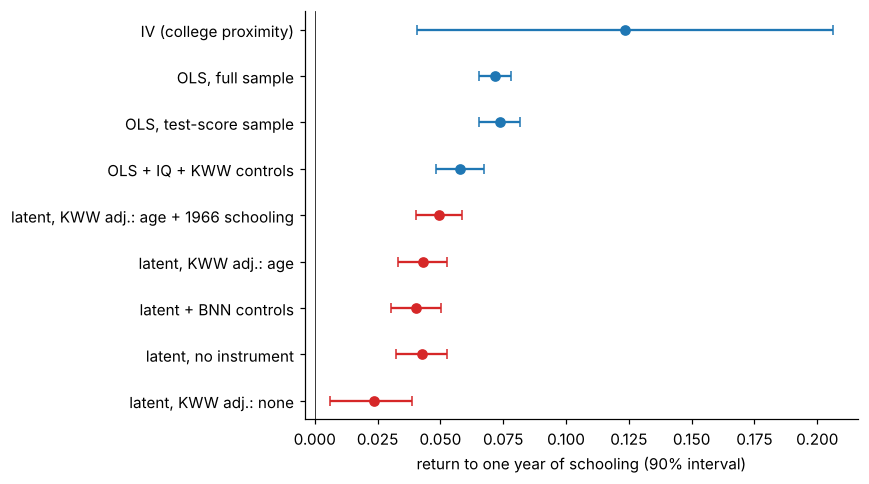

In [12]:
order = ["IV (college proximity)", "OLS, full sample", "OLS, test-score sample",
         "OLS + IQ + KWW controls", "latent, KWW adj.: age + 1966 schooling",
         "latent, KWW adj.: age", "latent + BNN controls",
         "latent, no instrument", "latent, KWW adj.: none"]
r = results.loc[order[::-1]]
fig, ax = plt.subplots(figsize=(8, 4.5))
for y, (name, row) in enumerate(r.iterrows()):
    color = "C3" if name.startswith("latent") else "C0"
    ax.errorbar(row["return"], y,
                xerr=[[row["return"] - row["5%"]], [row["95%"] - row["return"]]],
                fmt="o", color=color, capsize=3)
ax.set(yticks=range(len(r)), yticklabels=r.index,
       xlabel="return to one year of schooling (90% interval)")
ax.axvline(0, color="k", lw=0.5)
plt.tight_layout()
plt.show()

### How much of schooling and wages does ability explain?

From the preferred model (KWW adjusted for age):

* the reliability of each test, i.e. the share of its variance due to
  ability;
* the effect of one standard deviation of ability on schooling (years) and
  on wages (log points), holding schooling fixed.

In [13]:
pref = fits["latent, KWW adj.: age"]
post = pref.posterior
s_m = post["s_m"].values.reshape(-1, 2)
pd.DataFrame({
    "posterior mean": [1 - s_m[:, 0].mean() ** 2, 1 - s_m[:, 1].mean() ** 2,
                       float(post["lam_e"].mean()), float(post["lam_w"].mean())],
}, index=["reliability of IQ", "reliability of KWW (given age)",
          "1 sd of ability → years of schooling",
          "1 sd of ability → log wage (given schooling)"]).round(3)

,posterior mean
reliability of IQ,0.586
reliability of KWW (given age),0.598
1 sd of ability → years of schooling,1.533
1 sd of ability → log wage (given schooling),0.102


## 8. Takeaways

* **Modelling ability as a latent factor lowers the OLS return to schooling by about 40%.** With
  KWW adjusted for age at the test, the return is **4.3% per year** (90%
  interval 3.3–5.3%). That is against 7.2% for OLS and 5.8% for OLS with
  test-score controls. Ability explains about 40% of the OLS estimate,
  twice the share suggested by simply adding the test scores as controls.
* **Why the controls under-correct.** Both tests have a reliability of
  about 0.6: roughly 40% of their variance is noise unrelated to ability.
  A noisy proxy removes only part of the bias. The factor model combines
  the two tests and accounts for their noise.
* **Ability matters for schooling and wages.** One standard deviation of
  ability adds about 1.5 years of schooling and about 10% to wages at a
  given level of schooling.
* **The answer depends on how KWW is treated.** If KWW is taken as a pure
  ability measure, the return falls to 2.3%. That is too low, because KWW
  partly reflects the schooling completed by 1966, which the factor
  mistakes for ability. Adjusting for age at the test gives 4.3%.
  Adjusting also for 1966 schooling gives 5.0%, but that over-corrects,
  since 1966 schooling is itself partly driven by ability. A plausible
  range is therefore **4.3–5.0%**.
* **College proximity adds no information here.** Without the instrument
  the estimate is unchanged (4.25% against 4.32%): living near a college
  adds only 0.2 years of schooling, and identification comes from the test
  scores. The IV estimate (12.3%) is far higher, but its interval spans
  4–21%. It also measures the return only for men whose schooling responds
  to proximity, so the two estimates need not coincide.
* **The BNN control function changes little.** With a 2 × 10 network for
  the wage controls, the return is 4.0% (3.1–5.0%). Once ability is
  modelled, a linear control function is adequate. Sampling the BNN with
  full MCMC is feasible on 3,000 observations, though slow.
* **Assumptions.** The results rely on a single ability factor, on
  measurement errors independent of the schooling and wage errors, and on
  positive test loadings. They are an informed estimate under stated
  assumptions, not a final causal answer.